# ResNet50 ImageNet + CBAM — V08 paired five-seed experiment

Experiment ID: `EXP-RESNET50-CBAM-TRANSFER-5SEEDS-011`. Historical source: `Notebook/ResNet50/resnet50_transfer_5seed_008.ipynb` (EXP-RESNET50-TRANSFER-5SEEDS-008).
This notebook compares **the same fusion/head recipe** with `USE_CBAM=False` and `True` at each of five fixed seeds. Historical results are context, not paired ablation data. CBAM follows [Woo et al. (2018)](https://www.ecva.net/papers/eccv_2018/papers_ECCV/html/Sanghyun_Woo_Convolutional_Block_Attention_ECCV_2018_paper.php).

**Default: SMOKE; no five-seed training.** Validation is the only evaluation split. `RUN_FINAL_TEST=False` and `RUN_HISTORICAL_HOLDOUT=False` are locked. The Runtime cell restores the bundled `scripts/cbam_v08` source in Colab; no repository clone is needed. Install dependencies from its `requirements.txt` if prompted. Set `RUN_MODE='FULL'` explicitly to train. `VIEW_ONLY` reads completed CSVs and plots without training.




## 01 Config — set paths and mode here

In [ ]:

USE_CBAM = True
RUN_FINAL_TEST = False
RUN_HISTORICAL_HOLDOUT = False
SEEDS = [42, 123, 2026, 3407, 7777]
CI_LEVEL = .95
BATCH_SIZE = 16
DATASET_ZIP_PATH = None  # Optional exact V08 ZIP path; FULL discovers the shared-folder shortcut.
OUTPUT_ROOT = None  # Optional output parent; FULL checks shared-folder write access.
DRIVE_RESOURCE_ROOT = None  # Optional mounted path to Cashew_Leaf_model_result shortcut.
FORCE_DRIVE_REMOUNT = False  # Set True once if Colab reused a mount from the wrong account.
REPO_ROOT = None  # Optional existing clone; Colab otherwise uses bundled source.


## 02 Runtime and repository

In [26]:
import os, sys, json, platform, subprocess, importlib.util, base64, hashlib, zlib
from pathlib import Path
if RUN_FINAL_TEST or RUN_HISTORICAL_HOLDOUT:
    raise RuntimeError('Test and historical Holdout are locked in this development notebook')
if RUN_MODE not in ('SMOKE', 'FULL', 'VIEW_ONLY'):
    raise ValueError(RUN_MODE)
use_bundled_runtime = REPO_ROOT is None
if os.environ.get('COLAB_RELEASE_TAG') or 'google.colab' in sys.modules:
    if REPO_ROOT is None: REPO_ROOT = '/content/cbam_v08_runtime'
    if RUN_MODE == 'SMOKE' and OUTPUT_ROOT is None:
        OUTPUT_ROOT = '/content/cbam_v08_smoke'
    required_paths = [p for p in (OUTPUT_ROOT, DATASET_ZIP_PATH, DRIVE_RESOURCE_ROOT) if p]
    needs_drive = RUN_MODE != 'SMOKE' or any(str(p).startswith('/content/drive/') for p in required_paths)
    mydrive = Path('/content/drive/MyDrive')
    if needs_drive and (FORCE_DRIVE_REMOUNT or not mydrive.is_dir()):
        try:
            from google.colab import drive
            drive.mount('/content/drive', force_remount=FORCE_DRIVE_REMOUNT)
        except Exception as exc:
            raise RuntimeError(
                'Google Drive mount failed before any dataset or output access. '
                'Reconnect the Colab runtime and authorize the training account '
                'that owns the MyDrive shortcut, then rerun this cell. A shortcut '
                'cannot repair a drive.mount() credential-propagation error. '
                "For SMOKE set RUN_MODE='SMOKE'."
            ) from exc
    if needs_drive and not mydrive.is_dir():
        raise RuntimeError('Drive mount returned, but /content/drive/MyDrive is unavailable')
    if RUN_MODE != 'SMOKE':
        shared_link = 'https://drive.google.com/drive/folders/1it9ayE473c0lLgxhiNnguqIkKtceI5zf'
        if DRIVE_RESOURCE_ROOT:
            resource = Path(DRIVE_RESOURCE_ROOT)
        else:
            # MyDrive may contain both a real folder and a shortcut with the same name.
            roots = [mydrive / 'Cashew_Leaf_model_result']
            roots += sorted(p for p in mydrive.glob('Cashew_Leaf_model_result*') if p not in roots)
            resource = next((p for p in roots if (p / 'Dataset' / 'CashewData_Split (8).zip').is_file()), roots[0])
        resource_zip = resource / 'Dataset' / 'CashewData_Split (8).zip'
        dataset_shortcut_zip = mydrive / 'Dataset' / 'CashewData_Split (8).zip'
        if RUN_MODE == 'FULL':
            if DATASET_ZIP_PATH is None:
                candidates = (resource_zip, dataset_shortcut_zip)
                DATASET_ZIP_PATH = next((str(p) for p in candidates if p.is_file()), None)
            if DATASET_ZIP_PATH is None or not Path(DATASET_ZIP_PATH).is_file():
                visible = sorted(p.name for p in mydrive.iterdir())[:35]
                raise FileNotFoundError(
                    'V08 ZIP is not readable through the mounted training account. '
                    f'Tried: {resource_zip} and {dataset_shortcut_zip}; '
                    f'DATASET_ZIP_PATH={DATASET_ZIP_PATH!r}. '
                    f'Visible MyDrive entries: {visible}. Open the Colab Files panel '
                    'and set DATASET_ZIP_PATH to the real readable ZIP path. '
                    f'Shared source: {shared_link}'
                )
            print('V08 ZIP on mounted Drive:', DATASET_ZIP_PATH)
        if OUTPUT_ROOT is None:
            shared_output = resource / 'training_results' / 'current_dataset'
            own_output = mydrive / 'cbam_v08_results' / 'current_dataset'
            if RUN_MODE == 'VIEW_ONLY':
                OUTPUT_ROOT = str(next((p for p in (shared_output, own_output) if p.is_dir()), shared_output))
            else:
                # A shortcut can expose the ZIP while denying writes to the owner's folder.
                # Prefer the historical result location only after a real small write succeeds.
                import uuid
                try:
                    if not resource_zip.is_file():
                        raise FileNotFoundError(f'Resource shortcut has no readable V08 ZIP: {resource}')
                    shared_output.mkdir(parents=True, exist_ok=True)
                    probe = shared_output / f'.colab_write_probe_{uuid.uuid4().hex}'
                    try:
                        probe.write_text('ok', encoding='utf-8')
                    finally:
                        probe.unlink(missing_ok=True)
                    OUTPUT_ROOT = str(shared_output)
                except (OSError, PermissionError) as exc:
                    print('Shared results folder is not writable; using training-account MyDrive:', repr(exc))
                    OUTPUT_ROOT = str(own_output)
        if RUN_MODE == 'VIEW_ONLY' and not Path(OUTPUT_ROOT).is_dir():
            raise FileNotFoundError(f'VIEW_ONLY results folder does not exist: {OUTPUT_ROOT}')
        if RUN_MODE == 'FULL':
            try:
                Path(OUTPUT_ROOT).mkdir(parents=True, exist_ok=True)
            except OSError as exc:
                raise RuntimeError(f'Cannot create persistent output folder: {OUTPUT_ROOT}') from exc
        print('Experiment output parent:', OUTPUT_ROOT)
elif Path('/kaggle/input').is_dir():
    if REPO_ROOT is None: REPO_ROOT = str(Path.cwd())
    if OUTPUT_ROOT is None: OUTPUT_ROOT = '/kaggle/working/cbam_results'
    if DATASET_ZIP_PATH is None:
        matches = list(Path('/kaggle/input').rglob('CashewData_Split (8).zip'))
        if len(matches) == 1: DATASET_ZIP_PATH = str(matches[0])
elif REPO_ROOT is None:
    REPO_ROOT = str(Path.cwd())
root = Path(REPO_ROOT).resolve()
bundle_bytes = base64.b64decode('eNrtfdty20iS6K9gNDHHgJuCSepmycONI0v0tGJs2WGpe3aGYmAgEqTQAgEMAEqiFYrYpxPneeP8yPmF/ZT9ks1LVaEKAC+y3bMzEdsXmwCqsm55q6zMrMctzwvjsPA8N11sHVlbV/Tvz34Ujv0iTOLtJI4WVuqHWTC2Tt4ef7CChzTIwlkQF7k1STLrxM9vgnvr5/ZrlytfxVfxRb9/emH1LHu327I63Z2W1W1391vWzm77oGUdwD/OVXzy/vjiwjs//tCnoldbflzcZP4oTvLgaqtlXW3dBH5U3Cz4IQr8iTcL4yDjZ+iRl83zgp/ipPBG1BUPC15tOdgP+LTlT6dZMPWLwBjisXxr0QgzaKlljZJZGgVF0JIjnoR3wXYewK9ySqxsHudqrOEsTbLCGuV36vcveQJNT7JkBmCKmyi8tsSXT/AovrjyHU2VfJkX0ERehKPcG4WyxCzwYy8fw5vDPVkwjRKYf1EAHzw/itRHf3TrT8N4qgrQi8DzYz9a5GGOU/Ohf/n57ETO/Gg0h5kXMz3zR1niTTr6U5oFozCH4esv4R02u9W6ii3452rr2o/8eAQLYwKMkqkXJXnOT+MwD/w88IrEEwvsjZJ5XGhwGopksFYGVpSta+/0bkpgFdQw6oXxJMgC6LI3yz1AbC+cwUTxt9TP/BlgQ5ZDPwo/Ejh1FY+DieXBitu4vC0rS+5z54hbuw+LG1pm+ua4SRrEML/3CDEO7iNA3x4iTsuCRpMxrBE8zovJ9muAbvlAUgIQActCaB1WCNpyT8NR8Sd6YU9agJhBNI6he3kPmx+0h+5tsMhtx6lWd+kvmJ8x1HTeGG+xqk3dLwemyAU+JIUcF/6GjtDI6L18fZ/D68cnfkR+cOdnIRCyFcaIWNewijhoL0680bU/45nlX442VKxJdAbViCK0b/w9GtNUUEdeqVZeWUDqWNF7xD+fkCT1euHEguW3bFH/lSVKS0p3iVi3HDfMvUkYBbZTaZhG6QM6Wp8BRYHv9bMsgSW42jo7P/n44dP7/mX/yHpk+E+EIkbV5B46jY24UeKPc1vvyZ3iKR7gWQZUr7oD/GjsFcFDYTfgiVMbIzQz4JFdbQ2t3/R4LmFO+YOYLfFNzp36nKdRKD9Sr662ls4C8MF5OQdpltwFMZK8NQvzmV+MblZPRj6wRfMt6qMzpDW954KAe+USX5Wc+2rrDX5zZ7fjMLODB2CRXnLbu8zmgWiCyBGrV+Z1DxvJXWTPgHkRVCR8d+9wGEguoj6S/ijyc8TmwfDXxmbiEvZaVKbBqJ550GceiGArG3AQ+Y8C4gJKBfHYlhzlM/OFidM0j0bTYkblVKpvoiJKru83eUwOWFGIqcqYePmwuQmQFa+pjlnOcMAghg4vhlqJoQmIuu36aYqTMoYJkUB6ChgD6vFfrfrczkF/6unSAhYOSFIModdrlCRWEIGSU4MFgjV/JURQFcgyUbUUlBCqJRwXBpkj7tnqo0O1ofAEpHWhy01jlhArec57xMvG81ma83x9CVObZrYlVgVoqmW9fKlrLbb6sppa9ToS0WiFJJWyVoZY9kY8eE2It4z2EAVBywOUY64DONOMl8yaWqqM+b4EyH0w8AeL9PCPlqUggzbUw4eBrmkNuSf0EX9UPpqrMA6iwseiXpr2Ou32S7teZbvehFMBo3o06cgOlcqe7BB8E8D1b039mXSq3dFqbNcbWNqdcfdG9me5dij7h4VFc6sKN3V4s6rb67uyDpMlciLhSNkuOSd9ckpsXcXsclBVA0DWjsYNmJ2u0KJNjbtOzladVzxTD2auAQtfAi9Zsq3zZI12dKa8bZmFGolQq+BYL3kuqmrhEt6uMweDPE1u/t2Y93di3M9h2tWamX9v8ZJXO1Aig+T2aUobEkLTvLdXJcuggOF6oGsFJBN6COIe991at2Bqs0J2rI6M2Esdt+tYaFf3hV+Fg7D1C6c3ZBNoIniUKL0mUYSMCV4TV+Gi+XhZwXxc5ydYxKNZWVarLLGk9hzQcnVtKrGM2wgUb5KZOvaLqjeg+iawFH5U2Y8obbs07AAjiSfhdMPNCM5kAlPo3YYxTpTYGQZiMWl/iNaaPA6KvTZsLXDl+//6aftz/+K8f7nX3r78fHx+8a7/eXuPyHi73X6No3AP99qH+NfuYcdpZGOAeEGcBwC40+1okE/75xd9gA1v68A7uwz8oNPGv/YP95cDDwuvCOOFBvrns8uG/h4wyN3dDv3VPXTEjjhP5hkgdAjagBTLsHnvoPqhJmhQrs2wYZ0VayyLeaqyXPEB6x6ytV7ZrsGhpXiSfWH6KHum62JCbHORSUcDhJtn0I5z4gwaYgHaIJaQRe0N7buFwuZfRz4rl85QqnLCZkX4J2woYhMojFTGTlAarnAjKH6v2A3aCgZWRrOl9/OF9/b4ov/+7LzvzsaI1WQBYbQuh3a19Vvd1Cf6Xw746gr/exfeBdYkfIBPtL+EEcN/ARpB9dq0r3Yt3SZxtXURBKWN5dUSIoZBovFxOgeyca3zxLoMctqw/whb62ReWFKn4P4AY/5Bb4Neub8kYYyb9G3rMRu84Bovhk9HclTYKH0qWeWL4ZG7O3mitygaofgbq2pTEaL3autw73fWyZk1wNIltxMwWpZ6TWxMvB4ugYbGCBTkBuuyfpCD0bCvgQc1rfrFyVn//PLs3dmJ97n/6ePny3XLTtZt3cwboO2UJ/gTz5gkRVoeKo+2YCu/8bPAKm4CKwchRUZjxotWZe0RP4rMD+NXQGiMHgTKz0Y30KtRAeu9nafBKJyA0ERTZhq41iUAJo48RoqHSQIxCPXzCnDsw0Uxh0LFdqGVQjrOc24XbcIGxjIS6zgbNGLsX133VYm1K7Zsf62O2ay5BN+hFs4DlhVY/+qv1W7ANIC8pwkfJ8Rd5jmTnCQOjRUJOnEZeZbjTIzdwvUCvTVrxkLUeewMpFxVLUKLGelXUgOhMWDJkqCwzO+ttlPHeWhqNVSpcjUD/RcAOmzC+3fHZ+9/+tz3js+P3//54uziGdwO1ghmHq3neclXUPBp/KSifzdwF2IrgsVQn9fzmCpPUOsgl8chQ65cK6H4AVvU2xKqZjkIBIBECRObZGNVAs9unBq//BzchcE9VBmHd+F4juRJdIKzj+u7rVFggObPHNRk6CfyggWS5yiaY6PuV7Kr92cfzi6PL88+nq9dsffhLCxoxXJNHJHNQ6d70BEiQKmS8DMYSzKLYXKWU3+TxALCW0iS+9vcj4twAs9+AcyQyI7OIrYBNLQDG6pRkBXwq1gw5zoNwktrQnNT8s+wxrzwdMTCUwqacfiOreW4XkW0EAIY1Ahgs4lO56iSgfplXSSTYuY/WMdrKb56FmYcZwTAgWNSRvjskOwNkb+AfYdxevgxC6dhTEjytzkw3BC1nxs/joMIUQ4n0qeXPhB3TFOLOH3+459OrEngI5+3Zn5aO0aEwnmSwdb4Hi25xUSc6GmvRcHbIPPz2leXXssy3G8+2fnf9MWdF2GUgz4/hRkEpkMvvRzUfkCBLzi9tpgemDZxZCYMtFcxm8dPeJTHcly2mJ33+Jc049IBmThYtmHJJ6DgBeM58Tc8yAuTXmcfjYS39342zXXrbz5P8ZzKVdVVIa0MQHQrAIGBA87ZlbdaJWAgjfV+b3UqxuXaQQedNRuVZnOQONeBlSZ5iCxJHA3KsV/Pw2gsBh7G6bzwQEVIA32cAlty6rcqMdjuDI0uq2JAEedAsuu7ymoJoCUwRWBf1m2c3McKOce4wePz0eqEGj0qbPmoFbsJx8AA4TtQmt1pVaq9etU4wdVmJiPc/QisOcXtm81wcYcEc+kLi0MWRHMyUoBKBY+kY409qF3v+WTUrYI0ulYH0jWBCJzjZdMXTF9URcqwNUr1xTXw17/DI6xCTENAEo9BQjd82Kv0cOa6+hkezGY4m8/MajDDq2tFyTQkw7ecAltOrw19cFB3rn8RTelwBM+jpmnQNvzMw+ksCcc2N+K0LHsb2uf/jKl1jCnCc/WlMyMa4g9ozkM45qSKSjrIaSDNEQS4AeDjy5dyAbXCjnAR0VERt/FNKPr0nXnkBTP/Z/NIaArm1MvDL0Hv4BvZowZLELT2poEt6uWBJVp0ilJ5/zuri0fEG/BLvVaVV5KAT8bjBg6UxHclIZ/AU/dU8RkNJBq4xkK4444L2YTBOwT6Pp8rq24IXmC/1JnzEXDnChX+fVkHEuFtEKTAxXPd3rExF1kFQJCTmgLkA6jX+oWNHKUlW3AUrH9s4tcQRhG+9u57Ez3K3W9Rhr4n8T9XN3oWx9D5PxSsKYRrmpGaca/OJs32voJwuSuNxNjUh9UFN6LsTZBeb9JQTCTK/90FXqvJXWATesE9kdj5eXft18ae6F2WfAHtEA0yfzn7ZPnzsbBuXZLFS9tl4skDkgkbbq4XBSqqsCOKg7sgg0mAnVswVluj5Y6U4uEG6BG+qecvYYquXOs2VcoDU/NDxTEefz758eznvnfx43F3b99CU8zB3sneYff12+67/d2d7vHJ8WG78/aks/96p9M/7Lw7PD7efXt6fHLS6Xffvdvb2T/Y2zk96Jwe77dPOrsH/QMcBuxU+yeX/VM+DqFNOR0rHO4ctqzX7R3442APFKz2AbrMdtq1Iw/pmWXZO+3XIIaQaXT3d1vWThcedzq79QowsQXV6HQJKJTr7OCvPfy1t4+nFGcfjv/Q9/r/etk/v0DrA/fP/SWd8skb/ArkzzSWv+6D61T8vJ7Br6fSgRCIBOaN/R8F8t4AULFKrvjsaP6S5M3EvpSAwtcNfky4eR7dzONbtOmQD2Tkz67H/pE1odMpu2P9/vdWtw1EcI1YU/Xiu3Hn6Rh9GgmIudu/cW+Ch3E4hbmyNT9IQMVwsvDINHsXGMPB39IZkt7za+FriG8a3QlZT3oHr8+T4l0yj8esLmkguBuo1GuTqKDzV5fM6baDqpiJq7W2TGc9SZkCsTWHPQZcOuzROTMd3JFB6MgatIcgtCNYJo1YhGsVWbFhWSSCP2krK0jR/UuY4rh5PLi4XyY1j6/ZdUA2vy8TN4wnCfnqVdeRjp+xIE4wnv40uWviMVQYzysH5CkeV8tVE0Cwb7g1dFz6WmsrIrzM8CQCJnsXlWJ6xOkgX0l2fj8FjuhdsBNlWaYzJHSAEfF0buhSOY/xIHZUBOJYABRm7i2sU6XbdQ9L6LPASuwBqKuOm88nk/DBJWsyII3oUpXqN+xcnMTbdCr/dX3jbnXVxGjI9PzZIbULGpZA6y3yvA/kcgwHWnuAY+PgwZaVnaH1A+xsFKn58cIu5imgrACSDwkHJJLDc+l8Il86GxAgK4uCwDQS5DflGKSsx3MdmmmPWQKycybXlvQWyfEd/yL3epbP+JKaNJhz8FCgo59H8gdd+gTfHQPAMCbxXOqt6pUkG70UmguSCDijUysuTmZhbjFKhPYZLavpnFZ4lestvWqkql+RpXwjXwCp00TythLxLSm4N2dVBej0AU6Mbc5MrXeVJag4vTMY5JRZENHJiVckdsNKr9nMz+PcnwQkOnCymwh7PVMWndkUM9TpSZQHy6ExnGcDrc8Rlc5tclkSr/DsDzRsAEI7IqB9bfrp3VGzZx1j6YR9tLkO4Se7ZLQkfBkZItWdZF4cLXfVE6pqfoMb1eXF+Dts29MFdjO5/sWWzQL86ilHUpSMYebH4SQg93j0xyCpLtcRbUQk5TdD7gYU+ogxVlSHdgR4+k1iBFigv0DjEG0JSpPQknATRD/gcZF/TVZdidbs/tsS/5eOlVSOjb/Y7SCezwIMIzKUmArTSLEkbBdAwijfKB78K4uJDtVPwvIG5SStitvNRC2NS7op5gXgstOAsjxsWYyeGkqpSZEFU1cnf5pN1889NMc9qHghxdSgIyTo8vnMLoUdTsCQqGMgekHyxg5ZBwxxnJkfTwN7zyHViFhttf4a8cjK5pNCRZZpSkhWReMyZChxWkhCu1KSnbPlsSi6aQN0Nrx09pX0y9mShjDcUwbk4r7R4+2kl0fhKMhtE7g2nRK+NmiCOc5hCwRIAqKrnHHulHAbRzs8FfACHzqG+MaGTY2V0fBooywEOKOD1tgD9z9MXC7H3pQ2vyKPvokSny11ztTbQdaZApF6sAozPmXuvfOBDWu49uCiAYBPC2w8lmpZ/OdO88nCyAdswJaxCyi1YK7th5Zld7uwf4U/HAqzuEnGvaut6xCPiP0M1ruFlclReKfriDEaOACTiaZDHiFQ+nzm4TlxFAWRh6aZvCeX8Piny4+XP533HZeW2y4XHYQ8utPhy1phafMI0DGTdZuVcbJZgH54OGfE58hRoHRYWxszKg0W4SzYwO4Bo00XKDriVJTObyOYONC/2NFB1rKVu18+SrIAMb4Spik+CC4rYyhFpKQ3oa9eDhtPANciZyQ60PcAQbIQFlI68jprbCtCCeXZDGzyGyWvQ2/cRMoktdJ50bKMoLGWOPwSeCmQnotKqcFPjv5pYz0hzZJrtIHG6HtB1gbuoePAxo+LUM9tKliyEoNOyD+aglVwOV3Ysk/YQR/lQimjPJ11auS7voFmd2mMFWi327BbtxvatbZlvxyQZ/ae2NRTM5J00Y+8x+27AqFtuUJ3QXad5EGvrYkNWgqDtWN9/HMb/3TxEIIODFadPVCdOAVFLLXhwWkC94rAoWBaBQ7HwrD83M8yf4HwYINTLNKgR7xEFFyYpSTyccEwLiqSEcCSYMSHBYlC8QtPxHZ32rQLgEIunxV1SAzurVaLdM8brPVqicRLOeqJwIP2WM6o/A4007ImLUuQKJVdScT2okVQJdH1JAq2rC9BlnjoBYW11UqP8GSpSvhLoShzFoUF8EQDvBgrDNrA8kFUDMsJxsMGUZbW16FZPWy310yf6W5LB424o0I1M3jwyXMIgKhusMqpZnXcvREHHXFKzcpy/8uyecZhZVXMmuSpIMGRIoRu0RNbbKEx94Q6rBhWz2BcLOC1Ez/BfhkvK2xaTi6G09UYtqixhJFrVfUDQiOOX0BIXTpmxEb0mH7xNat+nXTEl4n6YrgkkBQQReQj9ya5rmOJXnlZPFMPlqmlfS38qAeLuromavlYEXiGWbaZafaaX2v1zJwDcnaAymFmarkH5NTS5xJGcx4CBWvXKKzlwsCBlckveuScMyMqwtbLL1hOqyYLAq21V4EW3dfgdupwK4W6XEjX9TgZR0PZHSqriTzcRslgUdpO2hhIrjSnMs5ZhjWo/QtqQz2lHQzCalhNAWLAIyTraYrHYAElh0wRDV/xNRWoGg+lv6dcTkDhQchgsDxqzUmGXru96ySJbGwFWYb4Xj2NWcEQrJcvHzmY/tp7HD1dbR2ZLf4ioph/gRaXb2SfnLoTrbYxY2nlGP2yG8PL5bTza3KdGrWsOnbjGK0KEtfHXXIMriAEEGGH+M0flk9Q08BWTsXQ2JtztL1QD+Uu/vmJOWC3VA3jX5afA4oaKToY1xuTdDwjUYcIDtNsoeWg2AndK5HWu8+SeFrLGfANIxa5PtaS5GoqrBhf15DkBlS4EdajkkH0+RtFn7RBq0Kz/qVnuYfDDVKwVJd4QB6L5ZywbaycChHGqMYrsh+o4WGU39embiHhAiqMfxcUsGPRkKKqsOlEPprBAGaosvxujM+g76NjOUgY9F9XXuoatBX5SjRndS1BgCiFvhEYltLDTfxSx2yxpRd15M6bQwtVJJ6x/UbX8u1LeAvbzAsrjea5lQInBs0tRfV5e5qFY+F6/obDdcKcIgJExABxmusoMF0Nvs3ZWq/i3cyv5YZY8yRXe2PokfycBYCK4/koROtHsVD2XjSzYFYXmI1Pn/sX/UvyR7j1p1OgzVevqJlXODvaT5oo0ODzIoxgMjyajM6+1+3usl4TB8WrDifq+o4OUJfJbRBfoFVsUzco2oriX0naY/vRN3k9SXD8O0nxGL1sYYnXToG9bvLa4Q+Do5YG/EjBbllHw+/mtUOwlc+N6DO+hl6Xb5NUO8cjrySPjQSsQ8xBm8MVIWaGOxPGlxafOIbAqjKaZNk1iVq2JmHR4VyVbnA51z72ShR3qRvoeR1eniF+nahibDHlDtk11g8v2WZHcAMMRNf9OBklkP15vCm/2hK2QMUzrgEnrzGSpaf1zZVvGwaFFg2gtFGQ54kaIZ360GGvrOky1xN+n50jPvy1O4foN3PYrVuyjeRQV1tv3388+WP/1Hv7Z+/i40+fT/pHHAfDg+adavCQJphE4fC19YBABcYJuVT2Ug1WOE+KmXfP8NFWJlQ0vkrrhTZRyvc98++9bHrttb3u3p6C+aDAXahIFnsg6PczBQy9i8IUhnSTZOEX3FxHMhEK6WbWD5bhqWRU/ZxwnJLttnfNOt2ldf6SJDPb3nbbgAzwB/meaw86kJ2lQC5B+ueRbHsHK++YdXeX1j2BQWZosHbRzUqvs4cpYcR08gE6Wn09fz7FqHkZ4Vw6siLo31qXfn5bQzsyF/tpGoXo5zEvEjS1I1taWNcLrjIBpi62RW8krOImpJNCIMB385j2S37EtjpGqjC+AyyywkIZQBKMEuf6AsF6imzsJYRhP0i1akTxIGJ+3kXksWuLKUhEEBSQL2ZlANg4ek0M4FbSsQWHLY/wRjd0YqcV7MrzAwGZCjHInOYYAQs4GhiPBLzq3mcRv2B3ANno/0NUOAyYWMPr7D5gEgDHFp0puZ9kokd6JhGtJXLyFQCF+LPLAkbfZJiX6t4fouTaj47vgNqmwSfQU0AJ6p7aZvf8tBEkKDHB2HCNH8GeJ8Z9j+wNrIFoeC7ie+zBCA2aRnekkqmiR4yomb1VDESaWbiqEeMo3ERRPpO+AKKGmYr2hiYgS4qf4hB09JltcJA2/OM4Ng3T0Szsijt9IEknfdm5C2XPlNJTmQFTSLhEsxRE2LPIkm4qnnwYUQoP5dCIkrLAwzP5jVSXaaCfjxdkezeDI9Y1DAq3VrO7riYauY3ADTyOr5f07gPYCtb8zVhOHYOczZBtSElFYkmJ0TFgOUVWg1oaBF8CNYcVP4yaMZbng+fsc//k7FOf/UjpPaXmgIcowx+dYHsX1ZsgTUY35Lv0+snYFopaXaPWXrC9b9bqdOnZzyJa95B3UVByWcajq60ZsGwF7gCrgyI5m6deCXXn6cnceKj8ImLr8R32CN9rR8DoWTJuG+S7xMkHgy+CZAFuY3dc2MeB+Hc10uHxeVnA6ZWAbSAUgzIEnHMgW9oNkFiltCADd/c1iubdvX38s70/NPKNoCEHdu4Dt9s9fPkS1gt+7Mofe/BjWMalaHbSStfKAWLvHpzNtGBBBQBI7nlKL5VG3XcD7erXVaU2UaNeG+UbNCcXs9qsB1kqOWb55ys4D3zYJFHwoa6Z86SQsjNihwIWN+dEVgBtFM3HaIpO+XyzXDvxt2G/V2p5r7I4KYtU3uRsxvkfdF3ooXbOihrX23OrTMoMBEFB7hMOdYBf10lxwyw8d1dpEQ9LlIcHp0auq/WEmR/PQeUSikJD9dMsSUFDtIEa9YVVRdUxeVXymxF0HE9PdqG1GgGD/FU0ggeTEzUpA+Kk/59HcrNr2oJdU1V5Xo6K0KaXBih+gwtgZmDDiL09jyy3MctwPG+FIrG0xyhu8RaVJIOZO7+CWsEEblG/eG9y498FVjkWAc9wJxWe15E2ZJqthpmic2NtiKuG5zyz00D01GOAvRDE/mtoQjs1TWiZTrO7XKcRoZ56aQJS6jqgcO1voGFBsT2zNzvt5t68flZvdmu9OTB1LJka7p9LwTI4UpLm7gSFOxQow2Otbe0zEgKgGx6Qcvc1e9ig095xKRCs09l3Dw4O6dIEd//1sIH9/o/+8w+l/6xWdED3Pkfc/ofRcgxVbZln2f+oMP+EKox0zqdEIZtIqE1wB6BvpAoskaiM/iWNNErVfzpJuVOTlPvNnek+qzOdZkHJolLd6WKcgF6AkoOZp4LRbZqEcbGNZpsyg6YM0iNnAZ9DWunEU/nYbx5lrXsrqwhrlqRaRHgZqELBaqUMbcy6dbQm2oPrjMNMzwUqXucyKkwrtiIlqJyKngGW7lx4RNCkUj+VWfNgiLKBPIg44rBnDdIySIRqZVNgdYDoL1HzpgAQFfmrFPG0GoKl9cDR3bLGeGKv1hLTNQuaTjkOTRSR0z3yoXCtkAkwXRL/CV1m1UkEcd+gHB+uCLMT80c2M/IeSGapyLPXU2XPPnmn/XfvjzEWsjEkj6NrxHxWlPIvE/YisFOQcvWYFcPvxVzDq61Pxyd/xCibD8fnZ+/6F5df7/Oy7Pqde+H3UXfDsO1G1w8Zrom/KcWBeXHLutmoNbI6jKelIsZRR6gEr8l27Trqi2WFksHsyZV9Nvw5BGBRUs/Jqk+in4/CsOrLIeoIDoZXVpkZIzjVp0VcBGT3nHII88U8laSkeJsNCUk+OlsVSiFj5NZytJlfYJ8wKUG6wF+IAGlUrAiwMG/tapnhDRtf4XUV/3z8+ez4/FLcvrXyZhTtyil08LEn4bRlcZAeebI15CQg5CC6EMlU6SoZLF2WfW7sJOYDL1Dq444KlTPtPfYLnRlEKHEa9jr7oLldXycPoD7hCRvq01i59GiPCsA2wGvteRQlOY2vHuelTQL7B3k8MvKAkle05Pq8tFQmTFRVw3LvQ/PnP9ARJPVifk2YiXpTRBGbBMtB764pBYXZ+yJMovykPNwFIIwjKCLQJAuvM7bxpebv6mOkk7xwQMQkkrGdwgPx/hSsoEZRjUj8paVfpFM6PEoccr7hbhxxqcL6O3IwIqQhUX0lWJfCncjrppBp84V7P60E57XF15zCVZQzUt1zhEpRpuc3m/AfXOgxZsxFp/3JPIpQ7/8FuRI8AxHlwOMC9Bh4jYf+r3GppK8xLHuU3vg998CpAaWuX/uZ/Uur0n7Lgj1G1qMC0mGOpObITwk99lfcsDFKYHuAMW0RcF6sNPMzELtU77Uu+zmi7gHYxm1u88F5C1nDW8EamCWQ+cIQI6JiEQL2UQwl4dfTkbUnM1BTitz/+P/Wo1wFmT/EzJcAgPC8meNKrrbo4j4xXd09kyCb+ZBGouJymDqFCrw36XRhhC4+8xqR2tR/5bUizRSwFvMFM6myEsU5DlrWbskqFOoa9yUJntCTNzqwtKM5VCsEdf2HGxwJ4obEqmnm0zpF9yoSSCtYReMaLspmuYQBAKgotnXyVPdYNBJtiSp1WpCtYLJ4McDCOjnTG0TnsAdZ7oIusZNo0VsIhkkY3hPpTf/z//67yiWsA4qCKUY8Pw9dm24iWL0xaZRBg9o1msfiybJ/5+CbTrtdcb43L9r8gE/Wu45efig6redKbrzHQd7WQBnVKU/TP1xnxS1i6HNLFlcgKZlRSpPVeZkFoImRmP2AVuWqqgtRRKbx+oQY3ebM5HaaOmua06dpeXNqIczm1Kw2NbdsYVZefnra/ZGDmmDi0REGyFLc16MtQ6NAkv1uCrSqIs06vobWlz09puc5SoqM34jyjbIymFJh2HAB1IqbFv9bblusXihJyRCW3bhYH6ZM3CACHiSgQTikIAO+vJaUN1ztr9TVcG1DzO7/C2hc7h5CA0G/ibL1UFeodvdWaFQPSzSqjbS/FbpVgyq2I4WawkVQPlHrbLPCqRnNTY2rjH7VkBBJnY3+vW7blFYLKa0+03JIJiiF1Kcg2+bF5+U6ssaJMN+gGKzKP1Ns1eSVjpUimHcZwTbuana0rUzndYVwcXNS3itXbkY4Jk+/8lm/Nhm5r/OtGxVcYgy4Du5CPi1RaVya472ewS9W8oxN+cZ/G+9YxgqW8BFkDNqOrs4UnsUY1MqU+Wh0gnTeaAtWKUIbvhWcAHfJktIqrKez15L4QMyhbGMtB0hWcYCle6x1FL+/t2qXJe7A4xfOk9pk5T5ar6yL0+reCqsz0wDC+l31q2AAkyQujK3hSlZQj/DvmCzBvIFXUqFOtMuYBkp3jWl0Qes5qBovYTvRUiRUEiURk/Odbu8mKqXDraaDLZNG1b3aE3kn2YIPzh7pz6dvIUgB7zmifMK3a+vMtZykmvbNlyA6zpL2UVgPMGD2biBOnUgBoBVGyKJ/w+bauMID6gus2dDFJUahLMxDd+ZNyQa8FbTHVDYR5+RilcRU1zLEbdqTCe0XPEFeT82DXNUp2A/mxYJk8PZ2ucdluF/XSYPwCd8ZV63//Lf/Z5U93QxYldB1SxTgA51P1Yh+gnZcTAAZ6IkeEGU8qpN7j4KgngwGIM5vJbGR8Y2NIBU0q2SNswlqqzxx063I6/pS68FzmMzrb2EylKEEjYCJP8Yw2M2E9qoI2eaI2DqFU8UKhWN0LfToFfZIJM6Hdyuy17Qo10gDA6igEFRAu7nMvDSa+Sl07y1K8kYsfBY6v8j8+xeINFBB05tf4GMsXOqC8YunTVvaUNi+hrVvpIkVoBcrQTdCEwvVTGIVRBgBWe2RCfV7U5dcuSXktbQfqnXDcKXZV4IH0j5yYcjCY2JPZHNEt5RdJTz58OwnWFhx6Han3XgZPuBlPnyFJ+1t7vE+K5E3Fo/l8JAf9jJ3fhgZwdNEE3gE9unsvTz3onDQ0pamdcowq7VEeln5UWkwptogJ3ip3lDRBJakFdlcB6AcCpWrAWvCn8gFN7KcDETd38deNPIAg0C5mFjSvg0WPU5fbmVH0mA9qCYDwNQad0GWB5VTuKXMdFff5u1qGpvc5iERa3s8dxL5sCLUscHRayM9ozhNLFcEk28l9/UkB8PGJLSVTOhG+lkJsaznrL9PRqSg1fG0momW1p7wzVX55GlBw9lRbUsimGg4k26Z6Kv0h7drzlZoPJzc+ip+xPl4USZ4eDEEHvp//t3i92WiB3xvP6pjicGLcplfwJy73ckT2Q5qyr+yxoc59C6ZTAzN3ieBo9ZxgOeT2lIOj5bUXWYUB70S51oxEY2xNDMe8q5VN7hUU/np7j3isF/EQ5Y34o1DfxonHFgBj9p5PyVnxBuELegJZleMkpHy5sZobli4GttZ6jJMygH0VmW1w/h7ch20tVN2gsN9zCthh1xLOuthDX6Q7pKUVqxleY0pA0U0I+xP4bNswOY6g6Pd4RIfzBHSHzUlbzUxb8tBgI5LHgqS8vJUVpH3m5hVdGhcvwLgOdzFMCJpCVd2jRuNUGyDbA+Frj+6wWQrbUpI9Ub/atCZhgiP4dORuruuKWCAYHQIhqDpPMU2jui/9lApSDDfM39Z1bL5q62L+s2N5YWNG5CRSReehuSKjtAbpuJ9bnr1oVpG175yVgHcQ/qUmLTi9pKUCUdSYALogqpe8G2fzb4sSy9GMQmnnstEutiMwnRRPnHW0Qa/moobq/I4l8dr1EW36okOGvOSL8XE1bOVIFAuaXizqzSj8V0IHBFdt+2K1/4jMEVy3JTT5sofnJEjXRQ3SWwWoFceimTkd02XrcjZxHrQVU8W9jxxH5VPbfIQ9K9VUOWMy+KUZ6MCkJYUS8CErYLGq4WJRPBHFQq8vA0Lj5cQC4kcsqsgaisMNTQ/qlWVpukcSw8eSIQS3yAZxteMoR8RGle89GaR0x33aALEDMtXW3/49BN6J66YcY8iIcS854tcAERGzzESmP6/Yc1meAGupxm6j0ocq3xzp+TU7qVJFI6AZdIoagBH87HvYepMdJMWI0CoSe4KdMRO4TWdP50eez+fXZy9fd/3Tvs/n530L2CQT5I70P2diLq5C5tZ5A3laHu9rtvtuO2rmHra6+24nT23Ix63AVV6vba708UShCRYYdfdv4oJA3q9jts5wPK89tu04Pj2EF+Wy0mAO273Kk7DiNrtdN0dhIp9zGfJLboI5hWvvotFXNwEwPA4JzI5tOZvMO8SaHXQnWuMxymve8L7PDK8lbTAxNfzqGi4FHemuxs/MyUy4by4yFvA+7brdtfFFa11AGzJ68XZG7DBsbDkYSABFO9axfpgc1fxnyFjOya2HXTcltWF/3fg/134f8+VRvp85YmAT978Vg5av7yVfI+dmtGjmb31cmn2b1EGsmJsy6PB8TiZ9DqOCatSs+JEsmP9YBVumk5s9xDvwtol9xzlSUa2lPxvoKzvVcAaY8D7ZV6CfqLqoR1jRfHOkIrCqs1ztXk7Oz/5+OHT+/5lX+qYoq62dDZlwsPtlOHPg8lSm7/8gBae8iiFgk6FYMsWxu6rbONxt3tkdZ5a1mOnu4O/ZBjiwyhIC22XZNTP8xXBirUojXmseR7lmJUWQGu3MTSHhh3AFhMvH3O0AJ6m+KBatDhDWR0qVA32yav1RMxPWW5VvhABQ9NYaYchTxXKrP969m+8RpPVkLmI7uGk8TRsY+Rq+wlV/pD54xCY2SVmoqH9ZwG/qmG9MvtKc5bvhitL0MJavxwUhd3f5sBL5UW9Wq0pdISqQPPuVPTKRjgtsQ2qxfPoyjFjO4PllNaIrnIG9pySEUwwHkr2QG4oHBc9quoA8e1UXu9OubeqcKYVELRcU1wqGlEDyHih9nFY7N4l6wVWI3vH6sHyugkJ414GyIX9bHEaoi0nyRZiDWdp3TpCNiv4wq7WuRR7tDOWwRWVhO7kKq3f6iZu7KDbTxTyinxq+FYEd7JnNdpA6EUVQ0ruClPG7FXDLLXLa6mmah/8Iol6GAFcu35KMsYjCrO4uBDRDaMkDfjlxZ/PL3/sX56dWD+dn11al/2LSyOOTihGpAaQAghVijnmg9xmR4jSmYpN/WeneenuyonRxQtGEUtiswxe4RhgHhvw1SdDfIoZvA3jsWmQ+DiZ4HkRBykUsNq4xyOl5g2G/BLCBGOZsi31MwwS9u99pFzQL2OOCRJbtLo5Qkl0M8hZEJ+eWKZ8JdIYPUPchxMLR8ZCqwSg26Dru7hqroJlyfzeyqBRslYsiUfVL0+prDqm9mN2jccd+ITJ/OiOEb7yHXbHs17nsCscAGcB7JaLgN4e7Ot2sGcnHtSiJc0Eg7UkhCrpWc+QL2eIoLDiRBzPykkoiH1OoZSNK6vYQUtfAq7j6jHduzAzHJKhJXEsfzZnJFBtP6K1lrGOtmkVPCwz7AAOlgW0l08DxK3hV3daBjhrblfEW6biggYhXoFQfdD7vSyeImIrcYsZzvdADaSDfw3pMO4J595unvt0VQy7Xk6tfUhGfl1xSFtyZFq8dGpebiMyxqOZvCHwu0xqoAB4pI5gigA6DLI5LXFJvuViLTnhprO4hrbkkq1sa7W4MCaD0hzoQkMMtS4mxCQ1BSl3Kpr/yqQilXtXUhcvocjt6so3Z0MgVhYAygRLNSq2rJrWTtExrqmpOJ1G9YaLGWrNxirf89S956l6X6/m6VsypcPlpQZHU/C99LXvoqutwLZuZVExIf9ydHNooYnyfmNS3q+nFfLQnq0WrlUKMWASOimTSjxHR2ScllrhGqKpEz/3C2c5iMfuCK1IoJ3kbB79BjXyw8fT/nvr4sPHP/YbFElcNTKLwt8ipbpQ1RQzIXjnH1kX7Z9yU8a1qPjx/cfjU/woTG6G2cY0aLG2ahUqTAH3yBmS6QRthGrGZMgVG7Yw5zl6R2JV0XjNtLWpvWqljajJgqNlAdTuOFK2mdplSOLEVifsB0HQq+/gwRuBhVpOyjs7RClCwqtj8WjyQWsH70yt58cmk0nci9kPVGT7f5C3zHBFEoDQx9iPl3iB5eOe+G6VcUvmK7I39VZDIWTtmWYgdQ+Qj4Oq9E/Y08baFzSGmUYw5M7zXBXRTV2xtQ0SE81dY83OFTsmHVXmCP9o4ZDzsTFcfL/NjTUMUJsELPiDKFgOuhwyzzrZ/WjqaxNSpncoLVYq5u564XFSIjKYiic9bUlQ1Arz3ZPwwahjkbf2itI1h7AGTBVbTJUcQ9jYc5UpGW8GyOloAhNFlFvR6v0EuvFQ7ybeCb1tVfto3BTNwYXqWkHJOAx2c3mfbLOnougxbDHjIHOtd/MoKnlNiB1HJTDEvqscFdc8DiDmAITgLSbyyb4uyYdxJeFML8X3E36TDX1FypANs3NxsfJiRllCXi5YIqeQkEJnEHuYKGu+RZDlsahiJymMVUv9o55z93jsz/5k09EJLAffOIVAWQjBNmrkL1BamonG8XYssc9McEfqXqR+lgcnUHuaZHjudYKCBWRGhmo7pc8X3RR6n36jFweM9wZCQxB3ctRAyig0aZktfY+NQ7W8CFK+/Sp4CEZz2u+CMvxLiLcVaEqGHuqLHmKoAeR2mbiELgUK00DaNXTTiyqPXlXcbfWK914nCg7dhFuCxTvIEhA0FMSK3hXsNN0ydakepdChOF/QqbzrADMZxNFCpDagl0JPKN87Ztono1OXQTbD+7KDj/G5f27LJCnAv+oZf8gNgsauX5qgQIloiWoLfYRyUSRpinuvxjGaQ6teYM7N97jlQb1b1ZNTYHoF3gVIkyM36eVa1YxJ2q22K0qJ7DSVjMqNU0IeAbCyqM7bVLJlzWNM/u1FWdUdjG/yUIPD5EjD2sXLBAQUC1Ws0o1h01Xn8qKPFG/LZAh4mwH6ui0DUzUfJVNMgoM2AK6/vbwqwsWbGzutsoz6uKoiqQbVFeQrvGUVmTVqCANw9+jyTxjVdkMB1DHsDhRDjg58LrfpRxrCezkc3VawFnvfCw74GUjkQqxpZsvVdRwtYWpD1quvo5jPBOb954/xpwia9efPp5qJjxu5nkunsVUCqnVzCLBoBnsNM2rqB6qXphWazLa8Z6lmauRMg3S9qrxmFccg7iPF37ULcVUyk+9iaf5+FsOaumkapavNGwbGpqSUyru69P3VkhNKpbSe5WHFjcAbhB9BE/q1V1RC5iVSN15Rkpzc2B7hPii/oYMcugQLd9W5vR4U3cZNuZYafJKdmrxfDn7FBV2btlHKW2hGv0nMyEvGM0fRVaKhwQupgrKe9WL4RPLFFfKFMowZHsJytgY8Lci8SJvHVE+Z/lUslyggFw/KXF01xF2V9couezKxFTfBCa00zaLRAdm40ocCBGRmKhGQAvoVnQnJ63qPrEeeMDM8onqv2VdcSL2R3d1kK9V7PhpFNpfhwKqQvEYen551e/Xy4LwVtjo9/yRPELLUclCcC3KgMEzGa2nCFxZuU/zk2qtwEYGZ6bCa1kCLA6QEf3rzK0MODaRvzBle7jvIuid6aa8YnUySWR+WTspN+x5Tj5J7INN3nyZE8jdS6/SBN3E+ZTM1Cq4Ms6hfp0mEEY2XRVmGpTZRiTOASk3qXSMVB7MUSFajZVoQ0W2gYH0A9TAnRSoDqjdEirk9Upm2BrciYJEiRaBbvPW/FU+DNqXDumWjs4jjfKpdOwu0WbnoxVwQgLjJejSPH3NEhioW0i8Uz3qD5zxzOgsrEiu5CzLKAehaZ3GeAmNnh+Qgn88oe+gc76oy5qcMkmVcnoSFbag2UjTh3r8nVJ1KAjFSeXt19bhVqlU9fc8J81LuNmmfWd5R33Fc0aWKl04dR/9e98CW0bst66XohrgSdrjBnbBrbzoVIAcyoHjYGFBYTS35qHp1RClBOnQh8a0MTbrD63kZj1tGJK4L9WfQ9aenGhYYFGKswm+ti2SejYJtJEHAB0xGq+kcrEQAlhyh8c7ic6wCI9BU5h7sycn5ubxvg63mwmlZakhCIZ50+D50GadRt7nzdiMeI24aySJWSzdVxXu2vrReHjWIgqb2dAnq3yuyEyFvttpLCHLQk0JMOmiEFpNj67sN8hqd4jYVYIpM9piKzmcHvZ5Iv4QIjEe03ji840uh207D7KgNnEhgAXsmu4ogA33LNnScFeHd8M+2uEu6U56d/6Zqh6BdQduVioY6Ic4pAQZ0oeyfM+gOZbzNM9cR4S1dxhXaD9bQ1brKQleXV6RsNTulVO2GQ0UVe0f1moSDceRIpdQOdgNHNKqw2bGjOs+vBUWBJBwcdYbVs6cm77XlB5JLEcX0ctvoRHPdhZ7Kvm44m1Fo0tTMVVuGnGpHRnLfJo3T1XC5tRt+lVpHmg8MvU3fE6OYpg0KKJm7upbJtgIK6LJU0FAtkE87z14f5afvq4UGnaM/tTFsd54irdnm/rCHdMDU4En67zVxCSyxikkQBJJfdKU8Vq4KxE3AsOlXBeaGR9bKuiQTK1efsraCfnq9RzRd586RZXYiH2qiuTwVYvGiJ56XGOvlASiE47zXsAvjXFm4S2vpTggZaBrwHW/kLPyoJ88zoJJHH3ODcvTy0kuC5hETFaDPSfglsO8Vyaz31NCB1zbgvfrW++9+zfh6c0xzI4/STHEkKFAzTBwp6tRTHzbYH44kUSwxTzx93VXpW0//BeHN3XM=')
if hashlib.sha256(bundle_bytes).hexdigest() != SOURCE_BUNDLE_SHA256:
    raise RuntimeError('Embedded source checksum mismatch; reopen the notebook')
bundle_files = json.loads(zlib.decompress(bundle_bytes).decode('utf-8'))
source_dir = root / 'scripts' / 'cbam_v08'
if use_bundled_runtime:
    source_dir.mkdir(parents=True, exist_ok=True)
    for name, content in bundle_files.items():
        target = source_dir / name
        if not target.is_file() or target.read_text(encoding='utf-8') != content:
            target.write_text(content, encoding='utf-8')
elif any(not (source_dir / name).is_file() for name in bundle_files):
    raise RuntimeError(f'Incomplete cbam_v08 source at {source_dir}; set REPO_ROOT=None to restore the bundled source')
sys.path.insert(0, str(root))
missing = [m for m in ('tensorflow', 'keras_hub', 'numpy', 'scipy', 'sklearn', 'matplotlib')
           if importlib.util.find_spec(m) is None]
if missing:
    raise RuntimeError(f'Install notebook dependencies before continuing: {missing}; see scripts/cbam_v08/requirements.txt')
if OUTPUT_ROOT is None: OUTPUT_ROOT = str(root / 'training_results' / 'current_dataset')
OUT = Path(OUTPUT_ROOT) / EXPERIMENT_ID
from scripts.cbam_v08 import CLASS_NAMES
from scripts.cbam_v08.reproducibility import environment
print(json.dumps(environment(), indent=2))
print('Repository:', root, 'Output:', OUT)


V08 ZIP on mounted Drive: /content/drive/MyDrive/Cashew_Leaf_model_result/Dataset/CashewData_Split (8).zip
Experiment output parent: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset
{
  "os": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "python": "3.13.16",
  "tensorflow": "2.21.0",
  "keras": "3.13.2",
  "keras_hub": "0.26.0",
  "numpy": "2.1.3",
  "scipy": "1.16.3",
  "scikit_learn": "1.6.1",
  "matplotlib": "3.10.0",
  "gpu": [
    "/physical_device:GPU:0"
  ],
  "tensorflow_build": {
    "cpu_compiler": "clang",
    "cuda_compute_capabilities": [
      "sm_60",
      "sm_70",
      "sm_80",
      "sm_89",
      "compute_90"
    ],
    "cuda_version": "12.5.1",
    "cudnn_version": "9",
    "is_cuda_build": true,
    "is_rocm_build": false,
    "is_tensorrt_build": false
  },
  "mixed_precision": "float32",
  "cuda_visible_devices": null
}
Repository: /content/cbam_v08_runtime Output: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/curre

## 03 Dataset — ZIP hash and Train/Validation manifest; Test metadata only

In [27]:
from scripts.cbam_v08.dataset_v08 import verify_archive, extract_train_val, manifest, dataset
from scripts.cbam_v08.dataset_v08 import EXPECTED, ARCHIVE_SHA256
print('Class order:', CLASS_NAMES, 'Expected counts:', EXPECTED)
if RUN_MODE == 'FULL':
    if DATASET_ZIP_PATH is None: raise FileNotFoundError('Set DATASET_ZIP_PATH')
    audit = verify_archive(DATASET_ZIP_PATH)
    DATA_ROOT = extract_train_val(DATASET_ZIP_PATH, Path('/content/cbam_v08_data') if Path('/content').exists() else OUT / 'dataset_cache')
    train_paths, train_labels, _ = manifest(DATA_ROOT, 'train')
    val_paths, val_labels, val_relatives = manifest(DATA_ROOT, 'val')
    print('Train:', len(train_paths), 'Validation:', len(val_paths))
elif DATASET_ZIP_PATH and Path(DATASET_ZIP_PATH).is_file():
    audit = verify_archive(DATASET_ZIP_PATH)
    print('V08 SHA256 and metadata:', audit)


Class order: ('anthracnose', 'healthy', 'leaf_miner', 'red_rust', 'not_cashew_leaf') Expected counts: {'train': (939, 803, 875, 1072, 1101), 'val': (308, 216, 264, 328, 314), 'test': (122, 118, 132, 158, 156)}
Train: 4790 Validation: 1430


## 04 Data and preprocessing — RGB float32 0–255, 224×224, train-only augmentation

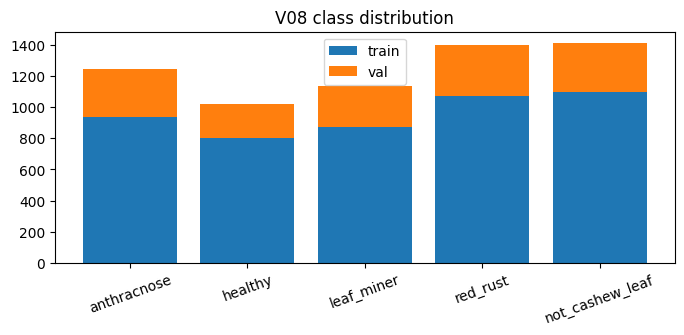

In [28]:
if RUN_MODE == 'FULL':
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.bar(CLASS_NAMES, EXPECTED['train'], label='train')
    ax.bar(CLASS_NAMES, EXPECTED['val'], bottom=EXPECTED['train'], label='val')
    ax.legend(); ax.set_title('V08 class distribution'); plt.xticks(rotation=20); plt.show()


## 05 CBAM and Student-t CI unit checks

In [29]:
from scripts.cbam_v08.smoke_tests import run as run_unit_smoke
from scripts.cbam_v08.cbam_layers import CBAM
from scripts.cbam_v08.statistics_ci import mean_sd_ci95, paired_ci95
SMOKE_RESULT = run_unit_smoke()
print(SMOKE_RESULT)


{'status': 'PASS', 'scope': 'SYNTHETIC UNIT TEST', 'checks': ['Student-t CI', 'paired seed IDs', 'CBAM shapes', 'finite gradients', '.keras reload']}


## 06 Model builders, trainability and source recipe

In [30]:
from scripts.cbam_v08 import model_resnet50, model_densenet121, model_deit_tiny
MODULE = {'resnet50': model_resnet50, 'densenet121': model_densenet121,
          'deit_tiny': model_deit_tiny}[MODEL_KIND]
print(json.dumps(MODULE.RECIPE, indent=2))
print('Paired variants: baseline_no_cbam, cbam')


{
  "stage1": {
    "lr": 0.0003,
    "epochs": 12,
    "early_patience": 4,
    "reduce_patience": 2,
    "min_lr": 1e-06
  },
  "stage2": {
    "lr": 3e-05,
    "epochs": 6,
    "early_patience": 2,
    "reduce_patience": 1,
    "min_lr": 1e-07
  }
}
Paired variants: baseline_no_cbam, cbam


## 07 Source parity and model smoke

Offline smoke builds a random-weight backbone to verify topology, CNN preprocessing, stage trainability and `.keras` reload. This does **not** verify the pretrained checkpoint or full source parity. FULL mode loads the actual ImageNet preset; if it is unavailable, stop with `BLOCKED_BY_SOURCE`. CNN GAP is explicit so CBAM precedes pooling.

In [31]:
if RUN_MODE == 'SMOKE':
    from scripts.cbam_v08.smoke_tests import run_model
    print(run_model(MODEL_KIND))


## 08–09 Paired Stage 1 and Stage 2 — FULL only

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Epoch 1/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.7221 - loss: 0.7480 - val_accuracy: 0.9308 - val_loss: 0.2590 - learning_rate: 3.0000e-04
Epoch 2/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.8881 - loss: 0.3403 - val_accuracy: 0.9413 - val_loss: 0.1905 - learning_rate: 3.0000e-04
Epoch 3/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9169 - loss: 0.2565 - val_accuracy: 0.9448 - val_loss: 0.1712 - learning_rate: 3.0000e-04
Epoch 4/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9257 - loss: 0.2252 - val_accuracy: 0.9503 - val_loss: 0.1593 - learning_rate: 3.0000e-04
Epoch 5/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9405 - loss: 0.1908 - val_accuracy: 0.9462 - val_loss: 0.1601 - learning_rate: 3.0000e-04
Epoch 6/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9382 - loss: 0.1834 - val_accuracy: 0.9427 - val_loss: 0.1681 - learning_rate: 3.0000e-04
Epoch 7/

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Epoch 1/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.8637 - loss: 0.4250 - val_accuracy: 0.9503 - val_loss: 0.1671 - learning_rate: 3.0000e-04
Epoch 2/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9455 - loss: 0.1745 - val_accuracy: 0.9469 - val_loss: 0.1557 - learning_rate: 3.0000e-04
Epoch 3/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9626 - loss: 0.1150 - val_accuracy: 0.9385 - val_loss: 0.1998 - learning_rate: 3.0000e-04
Epoch 4/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9689 - loss: 0.0981 - val_accuracy: 0.9587 - val_loss: 0.1417 - learning_rate: 3.0000e-04
Epoch 5/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9699 - loss: 0.0894 - val_accuracy: 0.9545 - val_loss: 0.1435 - learning_rate: 3.0000e-04
Epoch 6/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9731 - loss: 0.0802 - val_accuracy: 0.9510 - val_loss: 0.1534 - learning_rate: 3.0000e-04
Epoch 7/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - acc

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


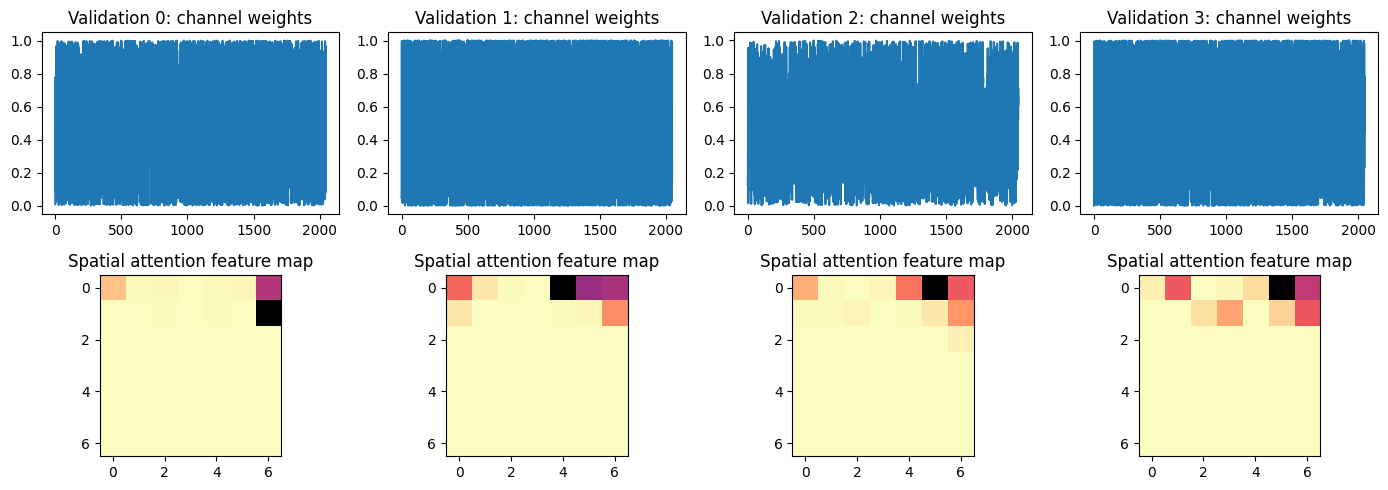

Epoch 1/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.6944 - loss: 0.8231 - val_accuracy: 0.9217 - val_loss: 0.2674 - learning_rate: 3.0000e-04
Epoch 2/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8816 - loss: 0.3585 - val_accuracy: 0.9259 - val_loss: 0.2231 - learning_rate: 3.0000e-04
Epoch 3/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9182 - loss: 0.2597 - val_accuracy: 0.9413 - val_loss: 0.1844 - learning_rate: 3.0000e-04
Epoch 4/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9240 - loss: 0.2239 - val_accuracy: 0.9427 - val_loss: 0.1785 - learning_rate: 3.0000e-04
Epoch 5/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9290 - loss: 0.2014 - val_accuracy: 0.9476 - val_loss: 0.1574 - learning_rate: 3.0000e-04
Epoch 6/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9470 - loss: 0.1709 - val_accuracy: 0.9503 - val_loss: 0.1548 - learning_rate: 3.0000e-04
Epoch 7/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - acc

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Epoch 1/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.8574 - loss: 0.4373 - val_accuracy: 0.9301 - val_loss: 0.2038 - learning_rate: 3.0000e-04
Epoch 2/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9470 - loss: 0.1695 - val_accuracy: 0.9490 - val_loss: 0.1663 - learning_rate: 3.0000e-04
Epoch 3/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9566 - loss: 0.1261 - val_accuracy: 0.9517 - val_loss: 0.1539 - learning_rate: 3.0000e-04
Epoch 4/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9647 - loss: 0.1073 - val_accuracy: 0.9329 - val_loss: 0.2098 - learning_rate: 3.0000e-04
Epoch 5/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9704 - loss: 0.0883 - val_accuracy: 0.9601 - val_loss: 0.1547 - learning_rate: 3.0000e-04
Epoch 6/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9795 - loss: 0.0647 - val_accuracy: 0.9608 - val_loss: 0.1392 - learning_rate: 1.5000e-04
Epoch 7/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - acc

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Epoch 1/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.6902 - loss: 0.8319 - val_accuracy: 0.9245 - val_loss: 0.2710 - learning_rate: 3.0000e-04
Epoch 2/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.8896 - loss: 0.3454 - val_accuracy: 0.9441 - val_loss: 0.2056 - learning_rate: 3.0000e-04
Epoch 3/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9136 - loss: 0.2591 - val_accuracy: 0.9385 - val_loss: 0.1859 - learning_rate: 3.0000e-04
Epoch 4/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9303 - loss: 0.2214 - val_accuracy: 0.9434 - val_loss: 0.1755 - learning_rate: 3.0000e-04
Epoch 5/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9361 - loss: 0.1932 - val_accuracy: 0.9392 - val_loss: 0.1854 - learning_rate: 3.0000e-04
Epoch 6/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9424 - loss: 0.1815 - val_accuracy: 0.9462 - val_loss: 0.1648 - learning_rate: 3.0000e-04
Epoch 7/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - acc

...

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Epoch 1/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.6992 - loss: 0.8039 - val_accuracy: 0.9294 - val_loss: 0.2784 - learning_rate: 3.0000e-04
Epoch 2/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8891 - loss: 0.3423 - val_accuracy: 0.9413 - val_loss: 0.2034 - learning_rate: 3.0000e-04
Epoch 3/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9200 - loss: 0.2573 - val_accuracy: 0.9483 - val_loss: 0.1765 - learning_rate: 3.0000e-04
Epoch 4/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9294 - loss: 0.2225 - val_accuracy: 0.9434 - val_loss: 0.1731 - learning_rate: 3.0000e-04
Epoch 5/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9386 - loss: 0.1916 - val_accuracy: 0.9503 - val_loss: 0.1592 - learning_rate: 3.0000e-04
Epoch 6/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9461 - loss: 0.1729 - val_accuracy: 0.9469 - val_loss: 0.1624 - learning_rate: 3.0000e-04
Epoch 7/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - acc

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Epoch 1/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.8557 - loss: 0.4487 - val_accuracy: 0.9343 - val_loss: 0.2028 - learning_rate: 3.0000e-04
Epoch 2/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9484 - loss: 0.1761 - val_accuracy: 0.9580 - val_loss: 0.1473 - learning_rate: 3.0000e-04
Epoch 3/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9593 - loss: 0.1294 - val_accuracy: 0.9587 - val_loss: 0.1441 - learning_rate: 3.0000e-04
Epoch 4/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9618 - loss: 0.1119 - val_accuracy: 0.9552 - val_loss: 0.1361 - learning_rate: 3.0000e-04
Epoch 5/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9727 - loss: 0.0834 - val_accuracy: 0.9580 - val_loss: 0.1487 - learning_rate: 3.0000e-04
Epoch 6/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9733 - loss: 0.0784 - val_accuracy: 0.9587 - val_loss: 0.1401 - learning_rate: 3.0000e-04
Epoch 7/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - acc

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


In [32]:
if RUN_TRAINING:
    from scripts.cbam_v08.training import run_seed
    from scripts.cbam_v08.reproducibility import environment
    from scripts.cbam_v08.dataset_v08 import sha256
    if not RUN_BASELINE_PAIR or not USE_CBAM or SEEDS != [42, 123, 2026, 3407, 7777] or CI_LEVEL != .95:
        raise ValueError('Primary paired five-seed protocol is locked')
    OUT.mkdir(parents=True, exist_ok=True)
    (OUT / 'selection').mkdir(exist_ok=True)
    lock = OUT / 'selection' / 'validation_selection_lock.json'
    rule = {'split': 'val', 'stage_checkpoint': 'minimum val_loss',
            'paired_seeds': SEEDS, 'guardrail': 'RESEARCH_ONLY / NO_DEPLOYMENT_DECISION'}
    if lock.exists() and json.loads(lock.read_text()) != rule:
        raise RuntimeError('Selection rule was already locked with different values')
    lock.write_text(json.dumps(rule, indent=2), encoding='utf-8')
    (OUT / 'dataset_audit.json').write_text(json.dumps(audit, indent=2), encoding='utf-8')
    (OUT / 'environment.json').write_text(json.dumps(environment(), indent=2), encoding='utf-8')
    (OUT / 'experiment_config.json').write_text(json.dumps({'id': EXPERIMENT_ID,
        'model_kind': MODEL_KIND, 'seeds': SEEDS, 'recipe': MODULE.RECIPE,
        'classes': CLASS_NAMES, 'dataset_sha256': ARCHIVE_SHA256,
        'pretrained_source': getattr(MODULE, 'PRESET', f'keras.applications.{MODEL_KIND}:imagenet'),
        'variants': ['baseline_no_cbam', 'cbam'], 'test_enabled': False}, indent=2), encoding='utf-8')
    (OUT / 'baseline_source_snapshot.json').write_text(json.dumps({'historical_experiment':
        HISTORICAL_EXPERIMENT, 'source_notebook': SOURCE_NOTEBOOK,
        'source_sha256': sha256(root / SOURCE_NOTEBOOK) if (root / SOURCE_NOTEBOOK).is_file()
        else SOURCE_SHA256, 'runtime_bundle_sha256': SOURCE_BUNDLE_SHA256}, indent=2), encoding='utf-8')
    (OUT / 'CONFIG_DIFF.md').write_text('# Paired comparison\n\nWithin this notebook the primary '
        'variant differs only by CBAM enabled/disabled. DeiT fusion baseline is new and '
        'historical EXP-007 A is reference only.\n', encoding='utf-8')
    (OUT / 'gate_status.json').write_text(json.dumps({'final_test': 'CLOSED',
        'historical_holdout': 'CLOSED', 'deployment_decision': 'RESEARCH_ONLY'}, indent=2), encoding='utf-8')
    (OUT / 'README.md').write_text(f'# {EXPERIMENT_ID}\n\nPaired five-seed Validation-only '
        'baseline versus CBAM. See experiment_config.json and aggregate/ after completion.\n', encoding='utf-8')
    revision = subprocess.run(['git', '-c', f'safe.directory={root.as_posix()}',
        '-C', str(root), 'rev-parse', 'HEAD'],
        capture_output=True, text=True)
    (OUT / 'source_git_commit.txt').write_text(revision.stdout.strip() or 'UNKNOWN', encoding='utf-8')
    for seed in SEEDS:
        train_ds = dataset(train_paths, train_labels, seed, True, BATCH_SIZE)
        val_ds = dataset(val_paths, val_labels, seed, False, BATCH_SIZE)
        for use_cbam in (False, True):
            run_seed(MODEL_KIND, seed, use_cbam, train_ds, val_ds,
                     val_labels, val_relatives, OUT)


## 10 Validation — only the 1,430 fixed images

Each completed seed writes predictions, per-class metrics, D2H, confusion matrix and checkpoint provenance. No Test or Holdout dataloader exists.

In [33]:
if RUN_MODE in ('FULL', 'VIEW_ONLY'):
    for variant in ('baseline_no_cbam', 'cbam'):
        for seed in SEEDS:
            path = OUT / variant / f'seed_{seed}' / 'validation_metrics.json'
            if path.exists():
                data = json.loads(path.read_text())
                print(variant, seed, 'accuracy', data['accuracy'], 'macro_f1', data['macro_f1'],
                      'D2H', data['disease_to_healthy_count'])


baseline_no_cbam 42 accuracy 0.9531468531468531 macro_f1 0.9511842700450863 D2H 13
baseline_no_cbam 123 accuracy 0.9566433566433566 macro_f1 0.9548650847361257 D2H 10
baseline_no_cbam 2026 accuracy 0.9503496503496504 macro_f1 0.9481242630129074 D2H 12
baseline_no_cbam 3407 accuracy 0.9517482517482517 macro_f1 0.9498554601543482 D2H 13
baseline_no_cbam 7777 accuracy 0.9524475524475524 macro_f1 0.9502313192751627 D2H 10
cbam 42 accuracy 0.9622377622377623 macro_f1 0.9607781513116619 D2H 11
cbam 123 accuracy 0.9636363636363636 macro_f1 0.9622545964562061 D2H 12
cbam 2026 accuracy 0.9657342657342657 macro_f1 0.9644589802236194 D2H 14
cbam 3407 accuracy 0.9594405594405594 macro_f1 0.9575300787327216 D2H 13
cbam 7777 accuracy 0.9552447552447553 macro_f1 0.9535776673327602 D2H 12


## 11–14 Five-seed aggregate, paired CI, figures and reports

The next cell requires all 10 completed runs; it never invents partial results. Charts display five dots plus CI or sample SD separately.

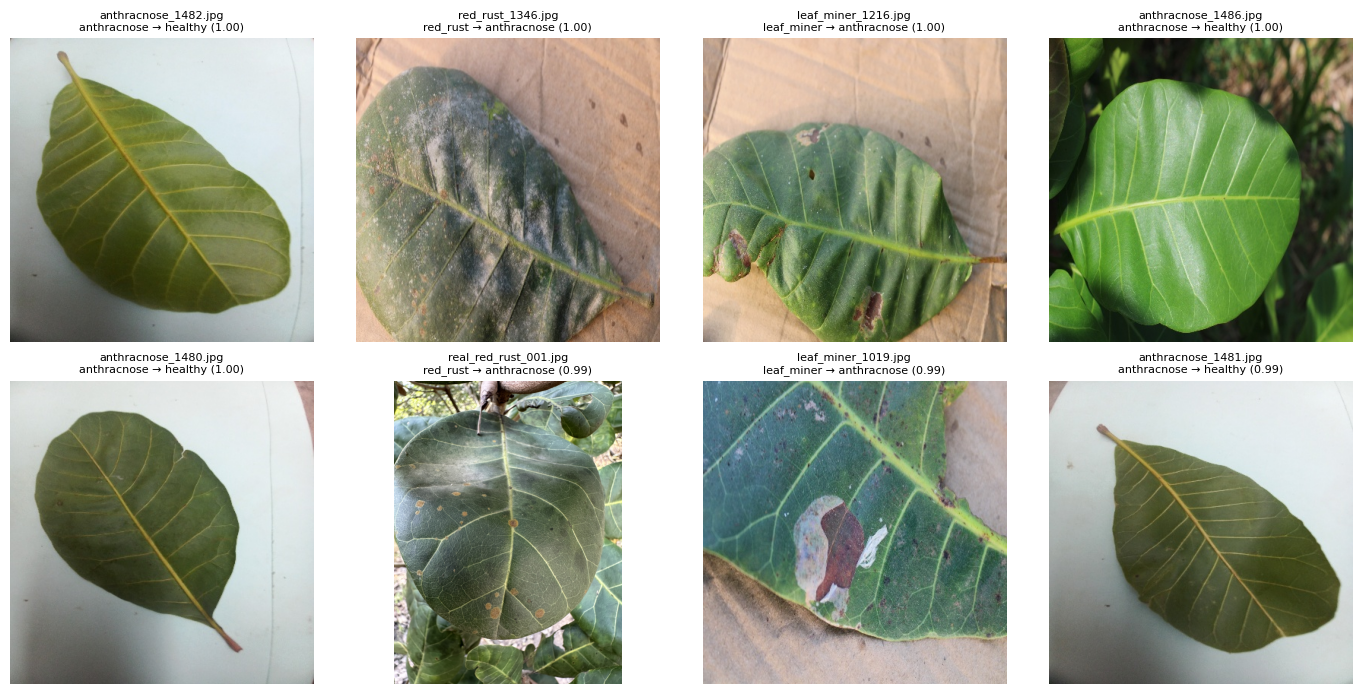

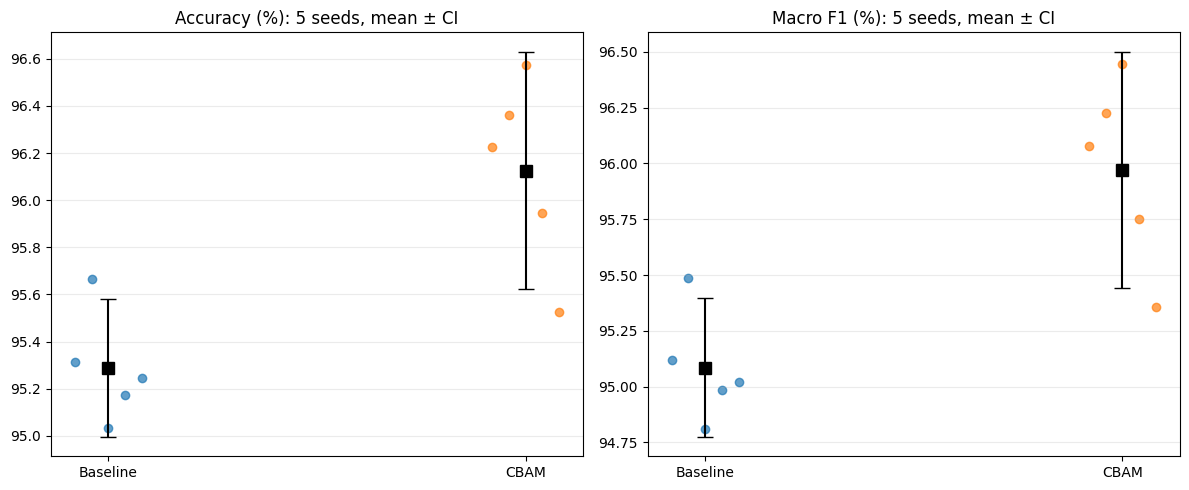

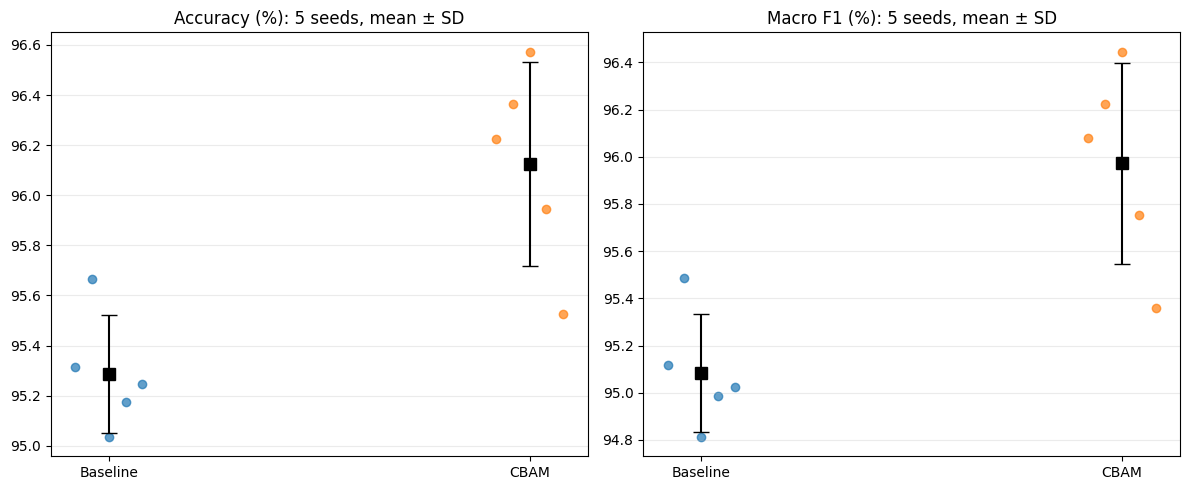

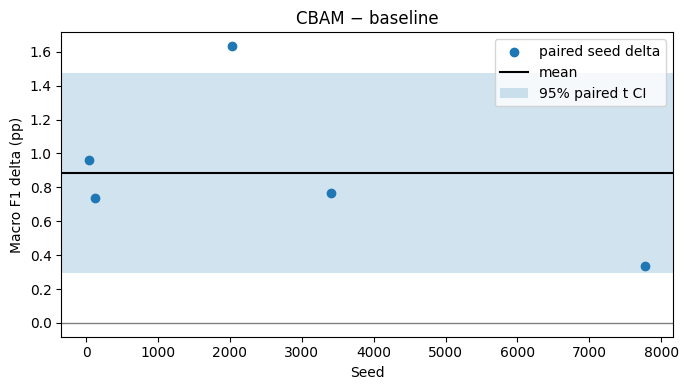

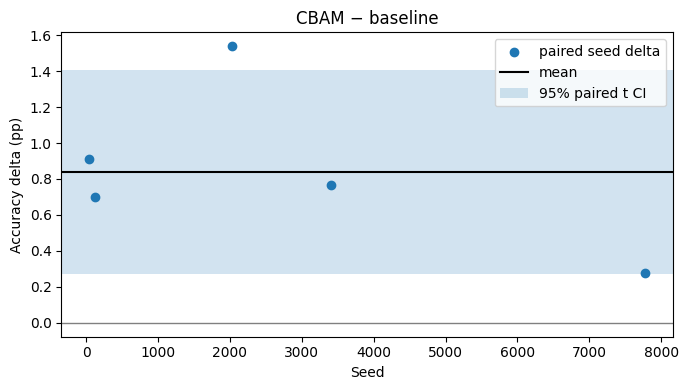

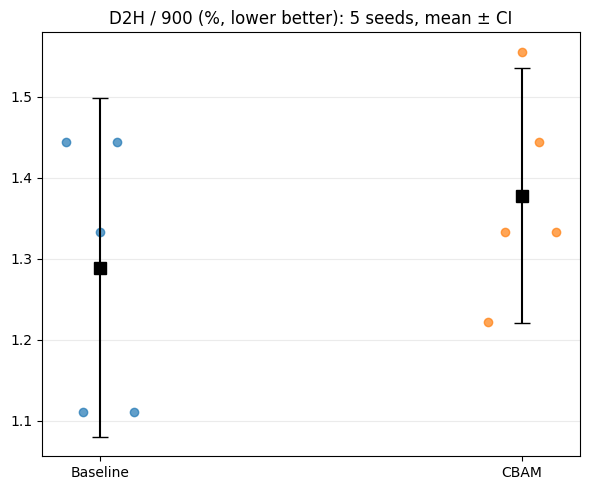

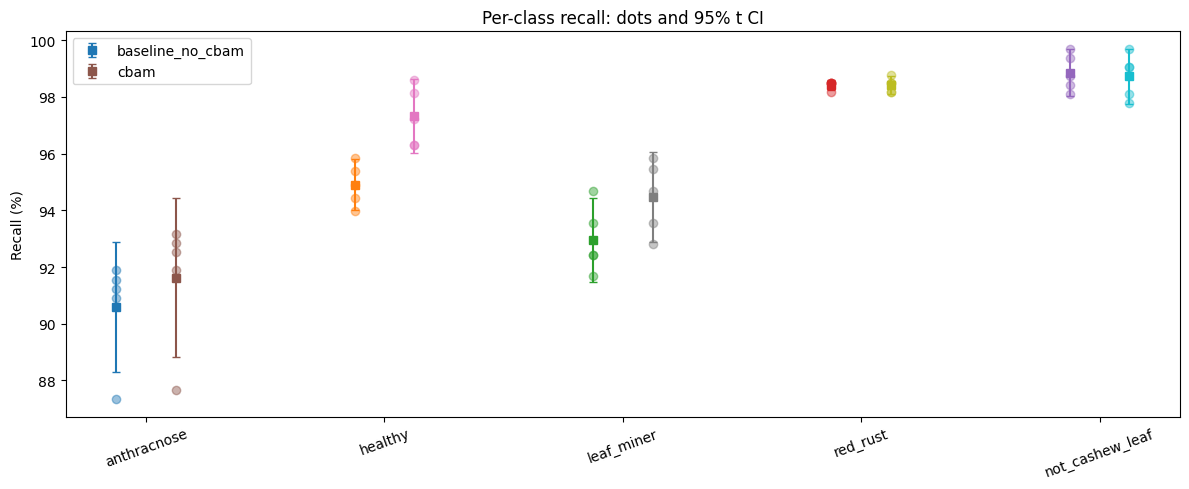

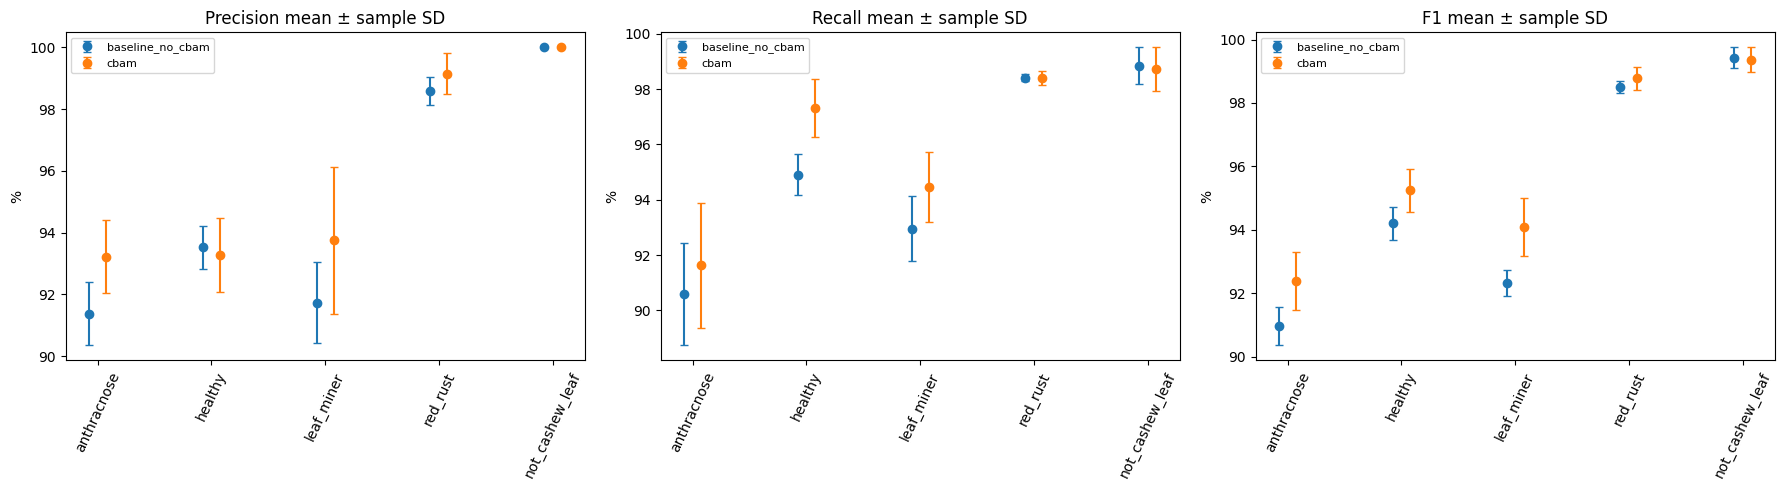

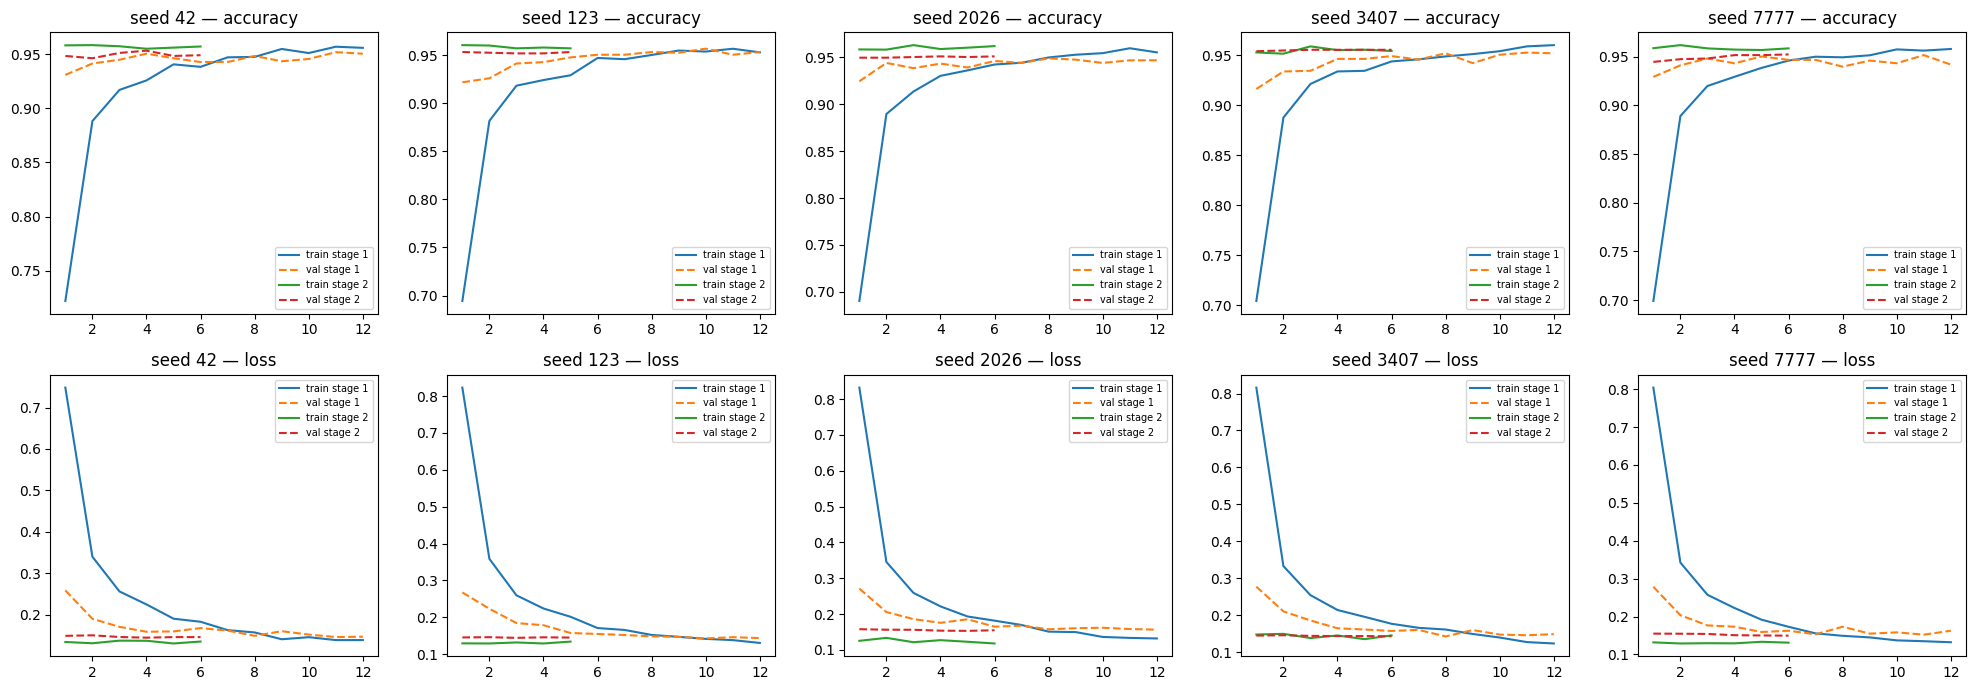

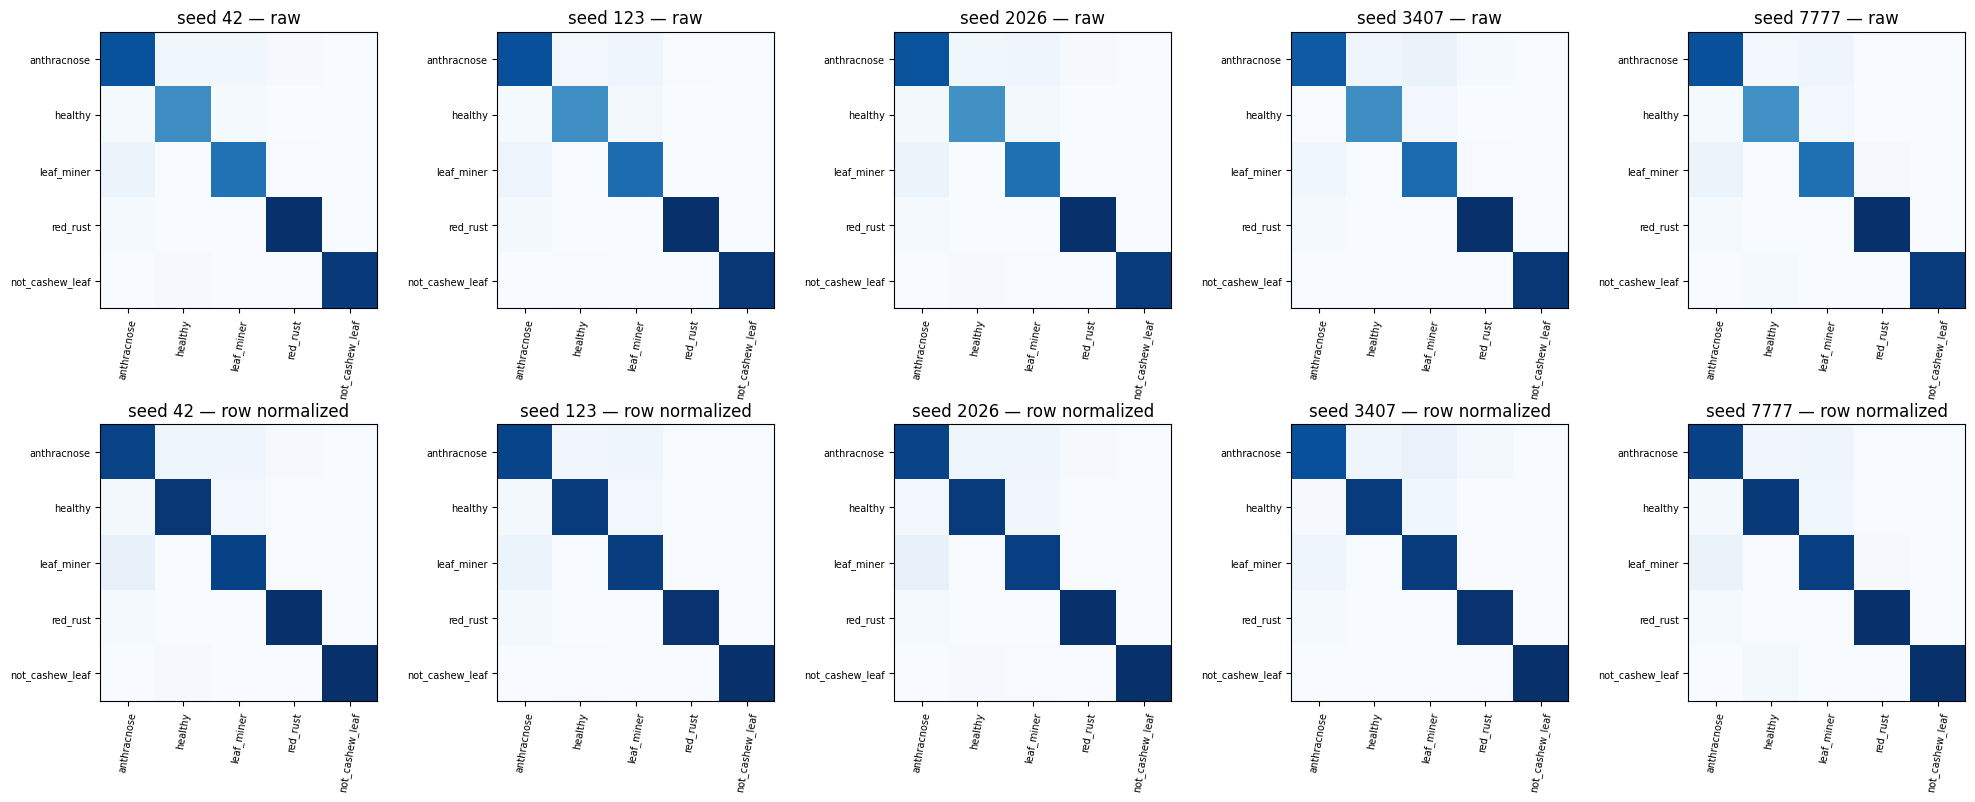

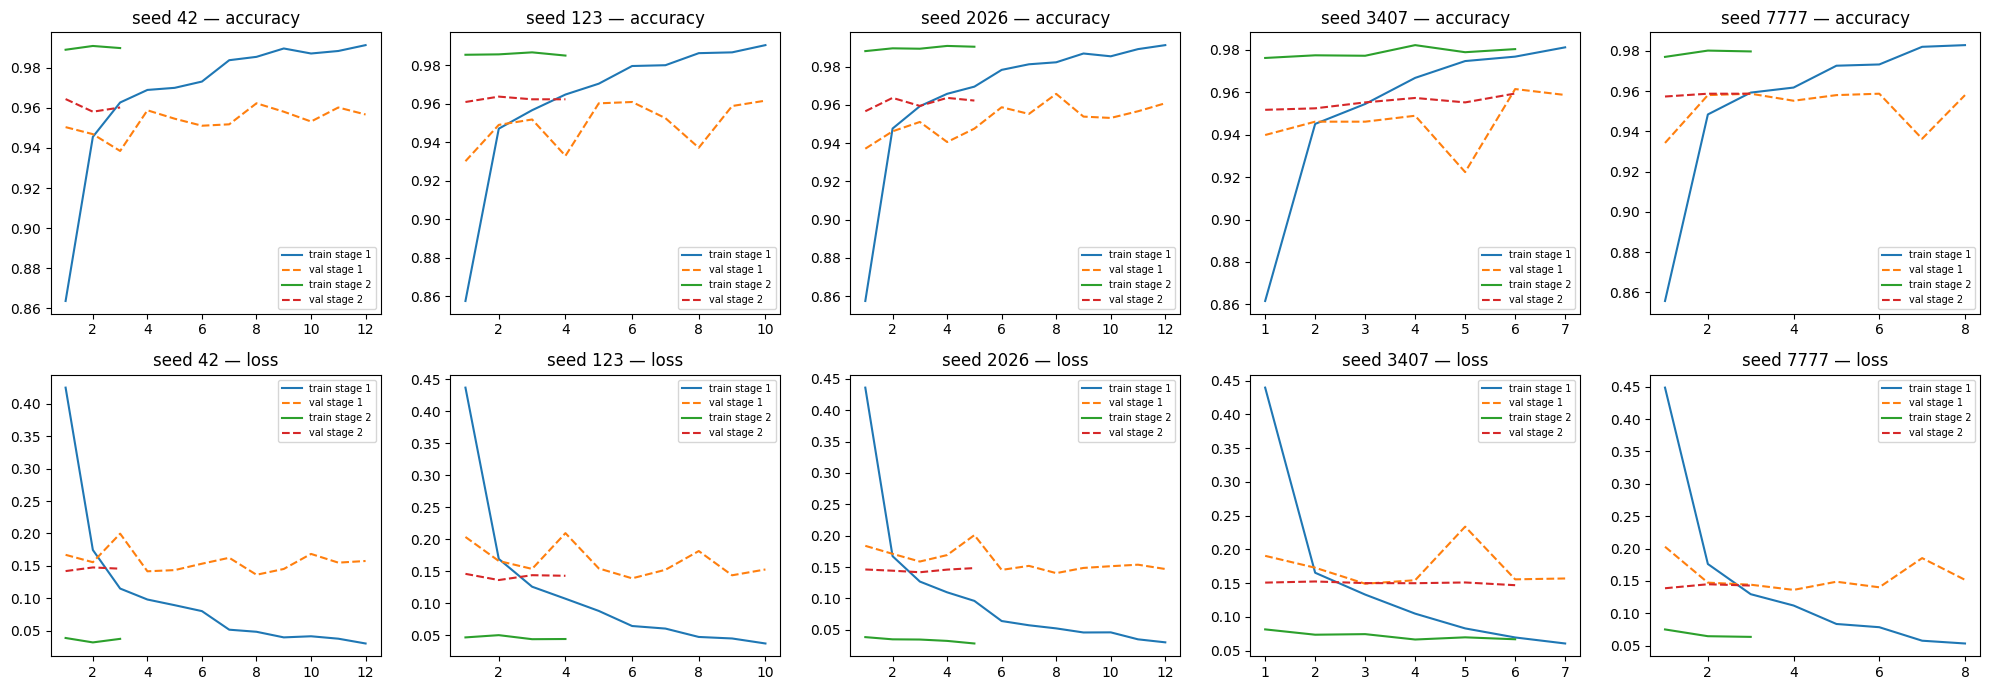

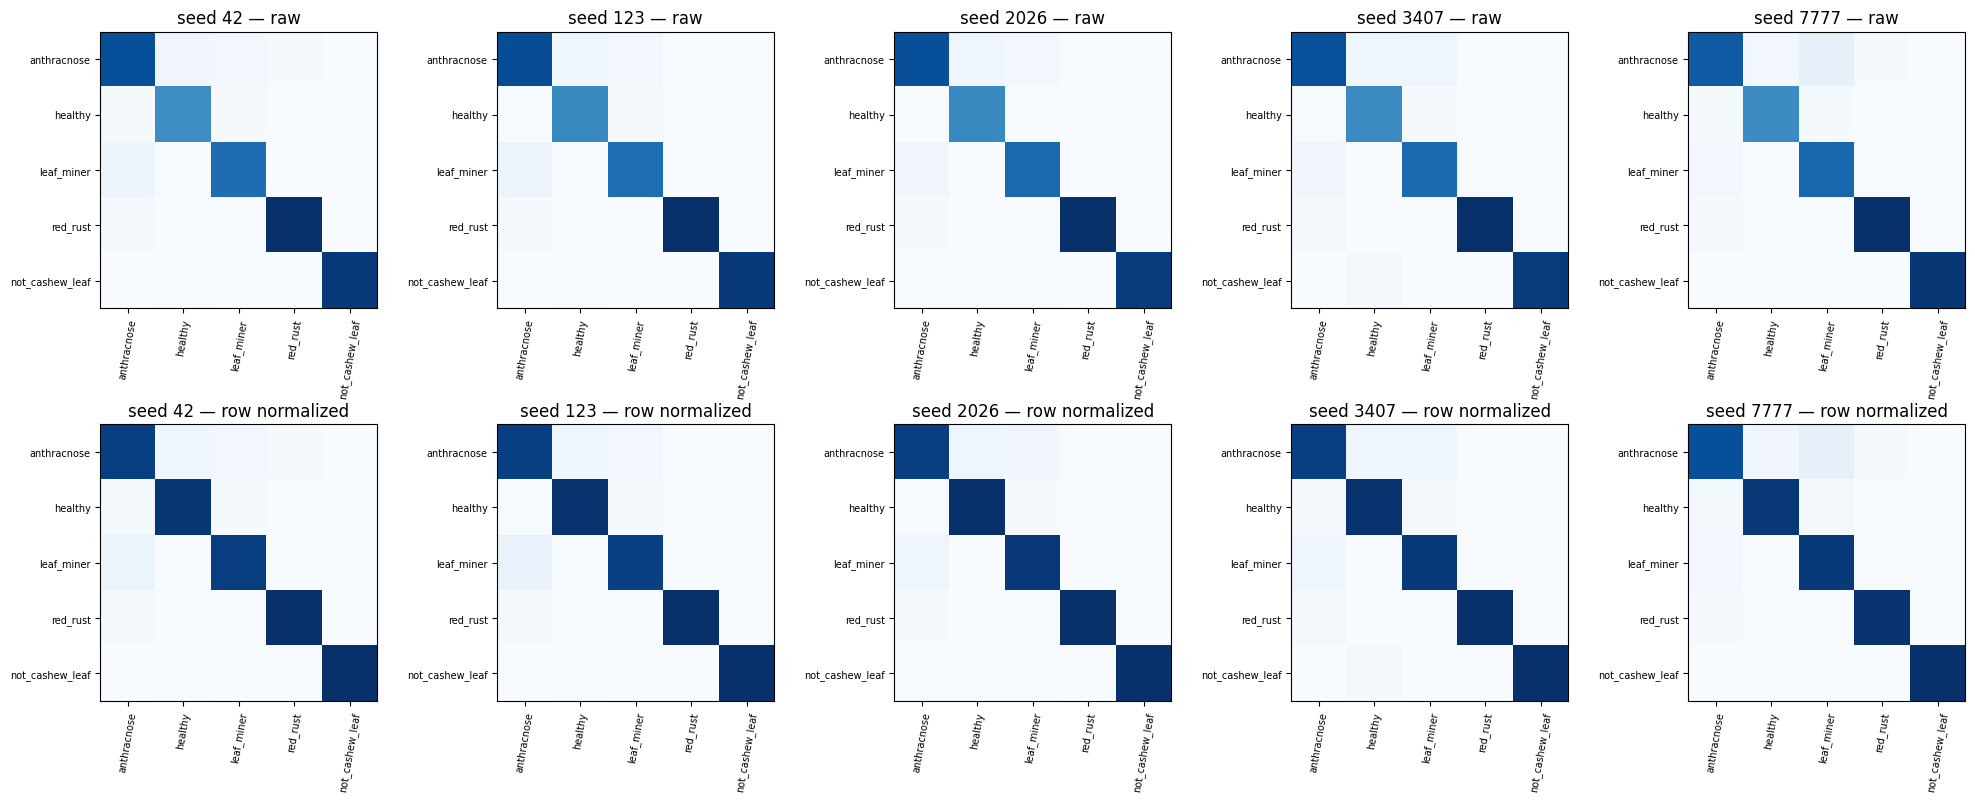

Figures: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-RESNET50-CBAM-TRANSFER-5SEEDS-011/figures CSV: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-RESNET50-CBAM-TRANSFER-5SEEDS-011/aggregate Package: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-RESNET50-CBAM-TRANSFER-5SEEDS-011/packages


In [34]:
if RUN_MODE in ('FULL', 'VIEW_ONLY'):
    if RUN_MODE == 'FULL':
        from scripts.cbam_v08.plots import plot_validation_examples
        plot_validation_examples(OUT, DATA_ROOT)
    from scripts.cbam_v08.aggregate import aggregate
    aggregate(OUT)
    print('Figures:', OUT / 'figures', 'CSV:', OUT / 'aggregate',
          'Package:', OUT / 'packages')
else:
    print('SMOKE only: no experimental metrics or figures created.')


## 15 Final Test and historical Holdout gate

Disabled by policy. Selection and research reporting use Validation only. This notebook has no Test prediction/evaluation cell.

In [35]:
assert RUN_FINAL_TEST is False and RUN_HISTORICAL_HOLDOUT is False
print('Test and historical Holdout gates: CLOSED')


Test and historical Holdout gates: CLOSED


## 16 Manual inference and artifact notes

Open `VIEW_ONLY` after the user completes all paired seeds. Read actual `predictions_val.csv` and the checkpoint hash for any manual Validation review. Checkpoints remain outside the small ANALYSIS package.

In [36]:
if RUN_MODE == 'VIEW_ONLY':
    print('Completed paired results:', OUT / 'aggregate' / 'validation_paired_seed_metrics.csv')
